# Crosslinker Kinetics

In [5]:
import numpy as np
import math                                                                         
from scipy.optimize import brentq  

## 1. Parameters and Initialization

In [6]:
# Kinetic parameters
k_off_0 = 0.05    # 1/s (baseline off-rate) [0.05]
k_on_0 = 0.0125   # 1/s (baseline on-rate) [0.0125]
KEQ = k_on_0 / k_off_0  # Equilibrium constant
CHI = 0.1     # Flory-Huggins parameter
THETA = 25 + 273.0  # Temperature (K)
dx_kT = 0.1 / (1.38065e-5 * THETA)       # Reactive distance over thermal energy: Delta x / (k_B T)

D = 0.1
MU0 = 0.0
VMOL = 0.15
RGAS = 8.31446261815324  # J/(mol*K)

# Concentration constraints
CACTIN = 0.0095     # Reference actin concentration (mM)
R = 0.1      # Initial total crosslinker ratio (cb + cf)
RBMAX = 0.25     # Max bound ratio
RFMAX = 1.       # Max free ratio (dummy large)

CR = CACTIN * R
CF_MAX = CACTIN * RFMAX
CB_MAX = CACTIN * RBMAX

KBULK = 1.e3

# Filament properties
mat_props_base = {
    'LAMBDA0': 1.0,
    'MU0STRETCH': 1.e8,
    'Lp': 16.0,
    'BETA': 0.5,
    'R0C': 0.014,
    'ETA': 0.5,
    'a_ratio': 1.2  # L / r0f ratio
}
B0 = 1.38065e-5 * THETA * mat_props_base['Lp']

# --- EQUATION FOR cb0 ---
def evalh(cb0):
    cf0 = CR - cb0
    thetaf0 = cf0 / CF_MAX
    # lhs - rhs = 0
    lhs = KEQ * cf0 * (1.0 - cb0 / CB_MAX)
    rhs = cb0 * (1.0 - thetaf0) * math.exp(-CHI * (1.0 - 2.0 * thetaf0))            
    return lhs - rhs

# Solve for cb0 using Brent's method (same as pullchem.f90)
cb0_root = brentq(evalh, 0.0, min(CR, CB_MAX))

# --- CALCULATE EXACT INITMU ---
cf0 = CR - cb0_root
thetaf0 = cf0 / CF_MAX
JC = 1.0 + VMOL * CR
JE = 1.0 / JC

INITMU = MU0 + RGAS * THETA * (
    math.log(thetaf0 / (1.0 - thetaf0)) + 
    CHI * (1.0 - 2.0 * thetaf0) - 
    (KBULK * VMOL / (RGAS * THETA)) * (math.log(JE) / JC)
)

print(f"Exact INITMU for Abaqus = {INITMU:.6f}")
print(f"cb0 = {cb0_root:.6f}, cf0 = {cf0:.6f}, thetaf0 = {thetaf0:.6f}")

Exact INITMU for Abaqus = -5885.596868
cb0 = 0.000202, cf0 = 0.000748, thetaf0 = 0.078734


## 2. Kinematics

In [7]:
# Deformation gradient (user-defined)
F = np.array([[1.3, 0.0, 0.00],
              [0.0, 1.0, 0.0],
              [0.0, 0.00, 1.0]])
# Determinant of the deformation gradient
J = np.linalg.det(F)
# Isochoric part of the deformation gradient
F_iso = (J ** (-1.0 / 3.0)) * F
# Inverse of the deformation gradient
F_inv = np.linalg.inv(F)
# Inverse of the isochoric part of the deformation gradient
F_iso_inv = np.linalg.inv(F_iso)
# Right cauchy green tensor
C = F.T @ F
C_inv = np.linalg.inv(C)
# Isochoric right cauchy green tensor
C_iso = F_iso.T @ F_iso
C_iso_inv = np.linalg.inv(C_iso)
# Left cauchy green tensor
b_cg = F @ F.T
# Isochoric left cauchy green tensor
b_cg_iso = F_iso @ F_iso.T
# Invariants of the isochoric right cauchy green tensor
I1_bar = np.trace(C_iso)
I2_bar = 0.5 * (I1_bar ** 2 - np.trace(C_iso @ C_iso))
# Stretch tensors (based on isochoric deformation tensors)
eigvl_Cbar, eigvc_Cbar = np.linalg.eigh(C_iso)
eigvl_bbar, eigvc_bbar = np.linalg.eigh(b_cg_iso)
U_bar = eigvc_Cbar @ np.diag(np.sqrt(eigvl_Cbar)) @ eigvc_Cbar.T
b_bar = eigvc_bbar @ np.diag(np.sqrt(eigvl_bbar)) @ eigvc_bbar.T
# Rotation tensor
R = F_iso @ np.linalg.inv(U_bar)
# Deviatoric projection tensors
I2 = np.eye(3)
I4 = np.einsum('ik,jl->ijkl', I2, I2) # I_ijkl = delta_ik * delta_jl
I4S = 0.5 * (I4 + np.einsum('il,jk->ijkl', I2, I2))
PROJEUL = I4S - (1.0 / 3.0) * np.einsum('ij,kl->ijkl', I2, I2)
PROJLAG = I4 - (1.0 / 3.0) * np.einsum('ij,kl->ijkl', C_inv, C)

## 3. Solve $\theta_f$

In [8]:
def thetaf_eq(thetaf):
    RT = RGAS * THETA
    Jc = 1 + VMOL * CR
    Je = J / Jc
    resH = (MU0 - INITMU) / RT + np.log(thetaf / (1. - thetaf)) + CHI * (1. - 2 * thetaf) - ((KBULK * VMOL) / RT) * (np.log(Je) / Jc)
    dH = (1. / thetaf) + (1. / (1. - thetaf)) - 2. * CHI + ((KBULK * VMOL) / RT) * (VMOL * CF_MAX) * (1. + np.log(Je)) / (Jc * Jc)  
    return resH, dH

In [9]:
maxiter = 40
tol = 1.0e-6
iter = 0
thetaf = 0.5# thetaf0  # Initial guess for thetaf

rootmin = 1.0e-8
rootmax = 1.0 - 1.0e-8

# Check if root is safely bracketed
resmin, _ = thetaf_eq(rootmin)
resmax, _ = thetaf_eq(rootmax)
if resmin * resmax > 0:
    print("Warning: Root is not bracketed. Using initial guess for thetaf.")
    print(f"resmin = {resmin:.6e}, resmax = {resmax:.6e}")

# Orient the search so that f(xl) < 0 (makes it easier for bracket updating)
if (resmin < 0.0):
    xl = rootmin
    xh = rootmax
else:
    xh = rootmin
    xl = rootmax
    swap = resmin
    resmin = resmax
    resmax = swap

thetaf = np.clip(thetaf, rootmin, rootmax)  # Ensure initial guess is within bounds

dxold = abs(rootmax - rootmin)
dx = dxold

resH, dH = thetaf_eq(thetaf) 

while iter < maxiter:
    # print(f"Iteration {iter}: thetaf = {thetaf:.6f}, resH = {resH:.6e}, dH = {dH:.6e}")
    # Conditions for activating bisection method
    # 1) Newton is out of bounds. Equivalent to (newroot - xh) * (newroot - xl) > 0.0
    cond1 = ((thetaf - xh) * dH - resH) * ((thetaf - xl) * dH - resH) > 0.0
    # 2) Newton not decreasing fast enough. Equivalent to new_step > 0.5 * old_step
    cond2 = abs(2.0 * resH) > abs(dxold * dH)
    if cond1 or cond2:
        dxold = dx
        dx = 0.5 * (xh - xl)
        thetaf = xl + dx
        if xl == thetaf:
            break

    else:
        dxold = dx
        dx = resH / dH
        temp = thetaf
        thetaf -= dx
        if temp == thetaf:
            break

    if abs(dx) < tol:
        break

    resH, dH = thetaf_eq(thetaf)

    if resH < 0.0:
        xl = thetaf
    else:
        xh = thetaf

    iter += 1
    print(f"Iteration {iter}: thetaf = {thetaf:.6f}, resH = {resH:.6e}, dH = {dH:.6e}")

print(f"Converged thetaf = {thetaf:.6f} after {iter} iterations with residual = {resH:.6e} and initial thetaf0 = {thetaf0:.6f}")

Iteration 1: thetaf = 0.500000, resH = 2.359546e+00, dH = 3.800109e+00
Iteration 2: thetaf = 0.250000, resH = 1.310933e+00, dH = 5.133442e+00
Iteration 3: thetaf = 0.125000, resH = 4.886354e-01, dH = 8.942966e+00
Iteration 4: thetaf = 0.070361, resH = -1.356850e-01, dH = 1.508823e+01
Iteration 5: thetaf = 0.079354, resH = -7.486098e-03, dH = 1.348811e+01
Iteration 6: thetaf = 0.079909, resH = -2.422450e-05, dH = 1.340124e+01
Iteration 7: thetaf = 0.079911, resH = -4.507044e-10, dH = 1.340096e+01
Converged thetaf = 0.079911 after 7 iterations with residual = -4.507044e-10 and initial thetaf0 = 0.078734


## 4. Update kinematics and aux derivatives

In [10]:
cf = CF_MAX * thetaf

Hres, dH = thetaf_eq(thetaf)
DthetafDmu = 1 / (R*THETA*dH)
# DthetafDt = ...
mfluid = D * cf * (1 - thetaf)
DmDthetaf = D * CF_MAX * (1 - 2*thetaf)
DmDmu = DmDthetaf * DthetafDmu

Jc = 1 + VMOL * (cf + cb0_root)
DmDJ = DmDthetaf * ((KBULK * VMOL) / (RGAS * THETA)) * (-1. / Jc)

# Volumetric stress components
Je = J / Jc
sefvol = 0.5 * KBULK * np.log(Je) ** 2
pv = KBULK * np.log(Je) / J
ppv = KBULK / J


/tmp/ipykernel_20750/1270189692.py:4: RuntimeWarning: divide by zero encountered in divide
  DthetafDmu = 1 / (R*THETA*dH)


## 5. Affine Network (Implicit Loop)

In [11]:
# Classic Newton-Raphson

# Calculations for 1 direction only
cbt = cb0_root
cbtau = cb0_root
Kon = k_on_0 * np.exp(CHI * (1 - 2*thetaf))
tol = 1.0e-6
maxiter = 40
delta_t = 0.5

dir = np.array([1.0, 0.0, 0.0])  # Direction of interest (x-direction)

def lambdaf(r0f, lambdai):
    return mat_props_base['ETA'] * (r0f + mat_props_base['R0C'])/ r0f * (- 1 + lambdai) + 1

def f_inext(r0f,lambdaf):
    a = mat_props_base['a_ratio']
    aux = B0 * np.pi**2 / (r0f * a)**2
    return aux * (((a - 1)/(a - lambdaf))**(1/mat_props_base['BETA']) - 1)

def dfdcb(f,cbtau,r0f,li,lf):
    a = mat_props_base['a_ratio']
    etac = mat_props_base['ETA']
    r0c = mat_props_base['R0C']
    aux0 = 2/5 * (cbtau)**-1 
    aux1 = 2 * f
    aux2 = etac * r0c / r0f * (li - 1)
    aux3 = B0 * np.pi**2 / (r0f * a)**2
    aux4 = (a - lf) * mat_props_base['BETA']
    aux5 = (f + aux3) / aux4
    return aux0 * (aux1 + aux2 * aux5)

iter = 0
li = np.linalg.norm(F_iso @ dir)

while iter < maxiter:
    print(f"Iteration {iter}: cbtau = {cbtau:.6f}, cbt = {cbt:.6f}")
    r0f = 1.6 * (cbtau*1.e3)**(-2/5)
    iter += 1
    lf = lambdaf(r0f, li)
    f = f_inext(r0f, lf)
    print(f"r0f = {r0f:.6f}, f = {f:.6f}")

    Koff = k_off_0 * np.exp(dx_kT * f)
    print(f"Koff = {Koff:.6f}, Kon = {Kon:.6f}")
    
    thetab = cbtau / CB_MAX

    Ri = Kon * CF_MAX * thetaf/(1 - thetaf) - Koff * CB_MAX * thetab / (1-thetab)
    print(f"Rbinding = {Kon * CF_MAX * thetaf/(1 - thetaf):.6f}, Runbinding = {Koff * CB_MAX * thetab / (1-thetab):.6f}")
    print(f"Ri = {Ri:.6f}")

    res = cbtau - cbt - Ri * delta_t

    if abs(res) < tol:
        print(f"Converged cbtau = {cbtau:.6f} after {iter} iterations with residual = {res:.6e}")
        break

    # Residual derivative
    DfDcb = dfdcb(f, cbtau, r0f, li, lf)
    DRiDcb = - Koff * (cbtau / (1 - thetab) * dx_kT * DfDcb + 1 / (1 - thetab)**2)
    DresDcb = 1 - DRiDcb * delta_t

    # Update guess
    cbtau -= res / DresDcb

    # Ensure safe update
    cbtau = np.clip(cbtau, 1e-10, CB_MAX - 1e-10)  



Iteration 0: cbtau = 0.000202, cbt = 0.000202
r0f = 3.033559, f = 0.132327
Koff = 1.246705, Kon = 0.013596
Rbinding = 0.000011, Runbinding = 0.000275
Ri = -0.000264
Iteration 1: cbtau = 0.000164, cbt = 0.000202
r0f = 3.294344, f = 0.112102
Koff = 0.762576, Kon = 0.013596
Rbinding = 0.000011, Runbinding = 0.000135
Ri = -0.000123
Iteration 2: cbtau = 0.000154, cbt = 0.000202
r0f = 3.380769, f = 0.106415
Koff = 0.664124, Kon = 0.013596
Rbinding = 0.000011, Runbinding = 0.000109
Ri = -0.000098
Iteration 3: cbtau = 0.000154, cbt = 0.000202
r0f = 3.385591, f = 0.106111
Koff = 0.659227, Kon = 0.013596
Rbinding = 0.000011, Runbinding = 0.000108
Ri = -0.000097
Converged cbtau = 0.000154 after 4 iterations with residual = 2.940749e-09


In [12]:
# Safe Newton-Raphson
# Calculations for 1 direction only                         
cbt = cb0_root                                              
cbtau = cb0_root                                            
Kon = k_on_0 * np.exp(CHI * (1 - 2*thetaf))                 
tol = 1.0e-6                                                
maxiter = 40                                                
delta_t = 0.5                                               
                                                            
dir = np.array([1.0, 0.0, 0.0])  # Direction of interest (x-direction)                                                    
li = np.linalg.norm(F_iso @ dir)                            
                                                            
def lambdaf(r0f, lambdai):                                  
    return mat_props_base['ETA'] * (r0f + mat_props_base['R0C'])/ r0f * (- 1 + lambdai) + 1             
                                                            
def f_inext(r0f,lambdaf):                                   
    a = mat_props_base['a_ratio']                           
    aux = B0 * np.pi**2 / (r0f * a)**2                      
    return aux * (((a - 1)/(a - lambdaf))**(1/mat_props_base['BETA']) - 1)                    
                                                            
def dfdcb(f,cbtau,r0f,li,lf):                               
    a = mat_props_base['a_ratio']                           
    etac = mat_props_base['ETA']                            
    r0c = mat_props_base['R0C']                             
    aux0 = 2/5 * cbtau**-1                                  
    aux1 = 2 * f                                            
    aux2 = etac * r0c / r0f * (li - 1)                      
    aux3 = B0 * np.pi**2 / (r0f * a)**2                     
    aux4 = (a - lf) * mat_props_base['BETA']                
    aux5 = (f + aux3) / aux4                                
    return aux0 * (aux1 + aux2 * aux5)                      
                                                            
# --- NEW SAFE-NEWTON (RTSAFE) KINETICS LOOP ---            
def kinetics_eq(cbtau_guess):                               
    r0f = 1.6 * (cbtau_guess*1.e3)**(-2/5)                  
                                                            
    # Handle compression (no force, no derivative)          
    if li <= 1.0:                                           
        f = 0.0                                             
        DfDcb = 0.0                                         
    else:                                                   
        lf = lambdaf(r0f, li)                               
        f = f_inext(r0f, lf)                                
        DfDcb = dfdcb(f, cbtau_guess, r0f, li, lf)          
                                                            
    Koff = k_off_0 * np.exp(dx_kT * f)                      
    thetab = cbtau_guess / CB_MAX                           
                                                            
    Ri = Kon * CF_MAX * thetaf/(1 - thetaf) - Koff * CB_MAX * thetab / (1-thetab)                                         
    resH = cbtau_guess - cbt - Ri * delta_t                 
                                                            
    DRiDcb = - Koff * (cbtau_guess / (1 - thetab) * dx_kT * DfDcb + 1 / (1 - thetab)**2)                                  
    dH = 1.0 - DRiDcb * delta_t                             
                                                            
    return resH, dH                                         
                                                            
# 1. Define physical bracket                                
rootmin = 1.0e-10                                           
rootmax = CB_MAX - 1.0e-10                                  
                                                            
# 2. Check if root is safely bracketed                      
resmin, _ = kinetics_eq(rootmin)                            
resmax, _ = kinetics_eq(rootmax)                            
                                                            
if resmin * resmax > 0:                                     
    print("Warning: Root is not bracketed.")                
    print(f"resmin = {resmin:.6e}, resmax = {resmax:.6e}")  
                                                            
# 3. Orient the search so that f(xl) < 0                    
if (resmin < 0.0):                                          
    xl = rootmin                                            
    xh = rootmax                                            
else:                                                       
    xh = rootmin                                            
    xl = rootmax                                            
    swap = resmin                                           
    resmin = resmax                                         
    resmax = swap                                           
                                                            
# 4. Initialize Newton
cbtau = np.clip(cbtau, rootmin, rootmax)  # Start from previous step guess (cbt)
dxold = abs(rootmax - rootmin)
dx = dxold

resH, dH = kinetics_eq(cbtau)
iter = 0

# 5. RTSAFE Loop
while iter < maxiter:
    # Condition 1: Newton step throws guess out of bounds   
    cond1 = ((cbtau - xh) * dH - resH) * ((cbtau - xl) * dH - resH) > 0.0
    # Condition 2: Newton step is not decreasing fast enough
    cond2 = abs(2.0 * resH) > abs(dxold * dH)
    
    if cond1 or cond2:
        # Fallback to Bisection
        dxold = dx
        dx = 0.5 * (xh - xl)
        cbtau = xl + dx
        if xl == cbtau:
            break
    else:
        # Proceed with Newton
        dxold = dx
        dx = resH / dH
        temp = cbtau
        cbtau -= dx
        if temp == cbtau:
            break

    if abs(dx) < tol:
        break

    resH, dH = kinetics_eq(cbtau)

    # Update Bracket
    if resH < 0.0:
        xl = cbtau
    else:
        xh = cbtau

    iter += 1
    print(f"Iteration {iter}: cbtau = {cbtau:.6f}, resH = {resH:.6e}, dH = {dH:.6e}")

print(f"Converged cbtau = {cbtau:.6f} after {iter} iterations with residual = {resH:.6e}")


Iteration 1: cbtau = 0.000164, resH = 2.409220e-05, dH = 2.337799e+00
Iteration 2: cbtau = 0.000154, resH = 1.161020e-06, dH = 2.118328e+00
Converged cbtau = 0.000154 after 2 iterations with residual = 1.161020e-06


# Analytical (Holzapfel 2014)

In [13]:
# ----------------------------------
# ---------- SHEAR STRESS ----------
# ----------------------------------
from matplotlib.lines import Line2D # Required for custom legends
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
# --- 1. Material Constants & Parameters ---
# Physical constants
# kB = 1.38e-23       # J/K
# T = 294.0           # K
# Lp = 16e-6          # Persistence length (m)
# B0 = kB * T * Lp    # Bending stiffness (J*m)

mat_props = {
    'K': 1000.0,
    'C10': 1.0, 'C01': 1.0,
    'PHI': 1.0,
    'a': 1.2,
    # 'L': 1.96, # CACTIN: 9.5
    'R0F': 1.6 * (48)**(-2/5),# 1.63, # 'R': 0.1'
    'R0C': 0.014,
    'ETA': 0.5, 
    'MU0': 386000000000000.0, 
    'BETA': 0.5,
    'Lp': 16.0, # 'B0': 294.0 * 16.0 * 1.38065e-5, 
    'LAMBDA0': 1.0,
    'NA': 7.66, # 'A': 1.2,
    'BDISP': 0.001
}

mat_props['L'] = mat_props['a'] * mat_props['R0F']
mat_props['B0'] = 294.0 * mat_props['Lp'] * 1.38065e-5

# Geometry constants (Table 1, Row 1)
r0_f = mat_props['R0F']    # Filament rest length (m)
# L = L      # Contour length (m)
r0_c = mat_props['R0C']        # Linker length (m)
r0_total = r0_f + r0_c # Total element rest length
n = mat_props['NA']      # Number density (m^-3)

# Model parameters
a = mat_props['L'] / r0_f        # Limit ratio (~1.20)
delta = 1/mat_props['BETA']        # Exponent
mu0 = mat_props['MU0']      # Stretch modulus (N) - governs extensibility slope

# Derived dimensionless alpha (Eq 72)
alpha = (np.pi**2 * mat_props['B0']) / (mu0 * mat_props['L']**2)

# --- 2. Set up Extensible Force Interpolator ---
# This solves the implicit Eq (71) once to create a fast lookup table.

def calc_lambda_from_force_dimless(f_star, a, alpha, delta):
    # Eq (71) from Appendix A
    term1 = 1 + alpha * f_star
    term2 = 1 + 2 * alpha * f_star
    term3 = 1 + f_star + alpha * (f_star**2)
    exponent = 1.0 / delta
    
    numerator = term2 * (term1**exponent) * (a - 1)
    denominator = term3**exponent
    
    # Note: The paper has a typo in some versions vs the provided image. 
    # The image form a*(...) - ... is correct for the physics.
    lambd = a * term1 - (numerator / denominator)
    return lambd

# Generate lookup table covering linear to highly stretched regimes
f_stars_table = np.concatenate([np.linspace(0, 20, 2000), np.linspace(20, 10000, 2000)])
lambda_table = calc_lambda_from_force_dimless(f_stars_table, a, alpha, delta)

print(lambda_table[-10:])

# Create interpolator: Input Lambda_f -> Output f_star_f
force_interp = interp1d(lambda_table, f_stars_table, kind='linear', 
                        bounds_error=False, fill_value="extrapolate")

# --- 3. Vectorized Integration Grid Setup ---
N_grid = 1000 # Higher number = more accuracy, slower speed
theta_1d = np.linspace(0, np.pi, N_grid)
phi_1d = np.linspace(0, 2*np.pi, N_grid)
THETA, PHI = np.meshgrid(theta_1d, phi_1d)

d_theta = np.pi / (N_grid - 1)
d_phi = (2 * np.pi) / (N_grid - 1)

# Pre-calculate geometric term for Sigma_22 (Eq 37 brackets)
Geom_Term_22 = (np.sin(PHI)**2 * np.sin(THETA)**3) - (np.cos(THETA)**2 * np.sin(THETA))

# Dimensional force scaling factor: w' = f* * (pi^2*B0/L^2)
force_scale = (np.pi**2 * mat_props['B0']) / (mat_props['L']**2)
# Overall stress prefactor: n * r0_total
total_prefactor = n * r0_total

# --- 4. Main Computation Loop ---
etas = [1.0, 2/3, 1/3] # The three compliance cases
gamma_range = np.linspace(0.0, 0.8, 150)
results = {}

for eta in etas:
    print(f"Computing for eta = {eta:.2f}...")
    stress_vals = []
    
    for gamma in gamma_range:
        # A. Global Kinematics (Eq 14)
        term = np.sin(THETA)**2 * (gamma * np.sin(2*PHI) + gamma**2 * np.sin(PHI)**2)
        LAMBD = np.sqrt(1 + term)
        
        # Define Compression Mask (lambda <= 1)
        tension_mask = LAMBD > 1.0
        
        # B. Filament Kinematics with Compliance (Eq 48)
        # lambda_f = eta * (r0/r0f) * (lambda - 1) + 1
        LAMBD_F = np.ones_like(LAMBD) # Default to 1 (rest)
        # Only apply stretch formula where global lambda > 1
        LAMBD_F[tension_mask] = eta * (r0_total / r0_f) * (LAMBD[tension_mask] - 1) + 1
        
        # C. Get Filament Force (Extensible Model)
        # Get dimensionless force f* based on filament stretch
        f_star_grid = force_interp(LAMBD_F)
        # Convert to dimensional force w'_f
        wf_grid = f_star_grid * force_scale
        
        # D. Assemble Integrand (based on image formula Eq 36)
        # Integrand = [ w'_f / (lambda * lambda_f) ] * Geometry
        # We use a small epsilon to avoid division by zero at exact rest lambda=1
        denom = LAMBD + 1e-9 # (LAMBD * LAMBD_F) + 1e-9
        integrand_grid = (wf_grid / denom) * Geom_Term_22
        
        # E. Apply Compression Filter
        # Force is zero if global lambda <= 1
        integrand_grid[~tension_mask] = 0.0
        
        # F. Integrate (Sum * dtheta * dphi)
        # Note: sin(theta) is already in Geom_Term_22
        integral_val = np.sum(integrand_grid * d_theta * d_phi)
        
        stress_vals.append(total_prefactor * integral_val / (4*np.pi))
        
    results[eta] = stress_vals

# --- 5. Plotting ---
fig, ax = plt.subplots(figsize=(7, 6))

# Define Colors for the 3 stiffness cases
# (Red, Green, Blue)
colors = ['blue', 'green', 'red'] 
eta_labels = [r'$\eta = 1$', r'$\eta = 2/3$', r'$\eta = 1/3$']
etas = [1.0, 2/3, 1/3]

# --- PLOTTING LOOP ---
for i, eta in enumerate(etas):
    # 1. Plot Semi-Analytical (Solid Color Line)
    # We use '_nolegend_' so these don't auto-populate the legend
    ax.plot(gamma_range, results[eta], 
            color=colors[i], 
            linestyle='-', 
            linewidth=2, 
            label='_nolegend_')

    # 2. Plot UMAT Results (Open Circles)
    # assuming abq_list_extensible[i] contains the data for this eta
    # umat_data = abq_list_extensible[i]
    # x_umat = umat_data[0,:]
    # y_umat = umat_data[4,:]
    
    # ax.plot(x_umat, y_umat, 
    #         color=colors[i], 
    #         linestyle='None', 
    #         marker='o', 
    #         fillstyle='none', 
    #         markeredgewidth=1.5,
    #         markersize=6,
    #         label='_nolegend_')
# --- CREATE SINGLE COMBINED LEGEND ---

# Group 1: The Methods (Black Line vs Black Symbol)
legend_elements = [
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='Semi-analytical (Holzapfel et al. 2014)'),# label='Semi-analytical - Eq. (A2)'),
    #Line2D([0], [0], color='black', lw=0, marker='o', fillstyle='none', markeredgewidth=1.5, label='FEM'),
    
    
    # Group 2: The Stiffness Cases (Colors)
    Line2D([0], [0], color=colors[0], lw=2, label=eta_labels[0]),
    Line2D([0], [0], color=colors[1], lw=2, label=eta_labels[1]),
    Line2D([0], [0], color=colors[2], lw=2, label=eta_labels[2])
]

# Create the single legend
ax.legend(handles=legend_elements, loc='upper left', frameon=True, fontsize=14)

# --- AXIS FORMATTING ---
ax.set_xlabel(r'$\gamma$', fontsize=16)
ax.set_ylabel(r'$\sigma_{22}$ (Pa)', fontsize=16)
ax.set_xlim(0, 0.81)
ax.set_ylim(-0.2, 5) 







ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
# plt.savefig('../figures/appendix_FEMval_s22_newlabel.pdf', bbox_inches='tight')


[1.19799559 1.19799609 1.1979966  1.1979971  1.1979976  1.1979981
 1.1979986  1.1979991  1.1979996  1.1980001 ]
Computing for eta = 1.00...


KeyboardInterrupt: 

In [ ]:
1.6 * (48)**(-2/5)

0.34011320016687757

In [1]:
import numpy as np
mf0i =  np.array([[0.91340055276979149,   0.39302183376737376, -0.10598711422607032], 
                [0.99333508166856521,    0.0000000000000000,  -0.11526237689074782],  
                [0.91340055276979149,  -0.39302183376737376,  -0.10598711422607032],  
                [0.86125615062406957,   0.21370819962774776,  -0.46104950756299135],  
                [0.86125615062406957,  -0.21370819962774776,  -0.46104950756299135],  
                [0.67049970118074342,    0.0000000000000000,  -0.74190979958249226],  
                [0.94930877132040004,   0.21370819962774776,  -0.23052475378149570],  
                [0.94930877132040004,  -0.21370819962774776,  -0.23052475378149570],  
                [0.81722984027590417,    0.0000000000000000,  -0.57631188445373915],  
                [0.91340055276979149,   0.39302183376737376,   0.10598711422607032],  
                [0.86125615062406957,   0.21370819962774776,   0.46104950756299135],  
                [0.67049970118074342,    0.0000000000000000,   0.74190979958249226],  
                [0.99333508166856532,    0.0000000000000000,   0.11526237689074785],  
                [0.86125615062406957,  -0.21370819962774776,   0.46104950756299135],  
                [0.91340055276979149,  -0.39302183376737382,   0.10598711422607034],  
                [0.94930877132040004,   0.21370819962774776,   0.23052475378149570],  
                [0.81722984027590417,    0.0000000000000000,   0.57631188445373915],  
                [0.94930877132040004,  -0.21370819962774773,   0.23052475378149567],  
                [0.80741343854372127,   0.56451258695467310,  -0.17149075318729928],  
                [0.74599377373332176,   0.40020664306107823,  -0.53228557410557398],  
                [0.56451258695467310,   0.17149075318729928,  -0.80741343854372127],  
                [0.53228557410557398,   0.74599377373332176,  -0.40020664306107823],  
                [0.40020664306107817,   0.53228557410557387,  -0.74599377373332165],  
                [0.17149075318729928,   0.80741343854372127,  -0.56451258695467310],  
                [0.71878401753890431,   0.58670508649440856,  -0.37299688686666083],  
                [0.58670508649440856,   0.37299688686666083,  -0.71878401753890431],  
                [0.37299688686666088,   0.71878401753890442,  -0.58670508649440856],  
                [0.80741343854372127,   0.56451258695467310,   0.17149075318729928],  
                [0.53228557410557398,   0.74599377373332176,   0.40020664306107823],  
                [0.17149075318729928,   0.80741343854372127,   0.56451258695467310],  
                [0.74599377373332176,   0.40020664306107823,   0.53228557410557398],  
                [0.40020664306107817,   0.53228557410557387,   0.74599377373332165],  
                [0.56451258695467310,   0.17149075318729928,   0.80741343854372127],  
                [0.71878401753890431,   0.58670508649440856,   0.37299688686666083],  
                [0.37299688686666088,   0.71878401753890442,   0.58670508649440856],  
                [0.58670508649440856,   0.37299688686666083,   0.71878401753890431],  
                [0.74190979958249226,   0.67049970118074342,    0.0000000000000000],  
                [0.46104950756299135,   0.86125615062406957,  -0.21370819962774776],  
                [0.10598711422607032,   0.91340055276979149,  -0.39302183376737376],  
                [0.46104950756299135,   0.86125615062406957,   0.21370819962774776],  
                [0.11526237689074785,   0.99333508166856532,    0.0000000000000000],  
                [0.10598711422607034,   0.91340055276979149,   0.39302183376737382],  
                [0.57631188445373915,   0.81722984027590417,    0.0000000000000000],  
                [0.23052475378149570,   0.94930877132040004,  -0.21370819962774776],  
                [0.23052475378149567,   0.94930877132040004,   0.21370819962774773],  
                [0.80741343854372127,  -0.56451258695467310,   0.17149075318729928],  
                [0.74599377373332176,  -0.40020664306107823,   0.53228557410557398],  
                [0.56451258695467310,  -0.17149075318729928,   0.80741343854372127],  
                [0.53228557410557398,  -0.74599377373332176,   0.40020664306107823],  
                [0.40020664306107817,  -0.53228557410557387,   0.74599377373332165],  
                [0.17149075318729928,  -0.80741343854372127,   0.56451258695467310],  
                [0.71878401753890431,  -0.58670508649440856,   0.37299688686666083],  
                [0.58670508649440856,  -0.37299688686666083,   0.71878401753890431],  
                [0.37299688686666088,  -0.71878401753890442,   0.58670508649440856],  
                [0.74190979958249226,  -0.67049970118074342,    0.0000000000000000],  
                [0.46104950756299135,  -0.86125615062406957,   0.21370819962774776],  
                [0.10598711422607032,  -0.91340055276979149,   0.39302183376737376],  
                [0.46104950756299135,  -0.86125615062406957,  -0.21370819962774776],  
                [0.11526237689074785,  -0.99333508166856532,    0.0000000000000000],  
                [0.10598711422607034,  -0.91340055276979149,  -0.39302183376737382],  
                [0.57631188445373915,  -0.81722984027590417,    0.0000000000000000],  
                [0.23052475378149570,  -0.94930877132040004,   0.21370819962774776],  
                [0.23052475378149567,  -0.94930877132040004,  -0.21370819962774773],  
                [0.80741343854372127,  -0.56451258695467310,  -0.17149075318729928],  
                [0.53228557410557398,  -0.74599377373332176,  -0.40020664306107823],  
                [0.17149075318729928,  -0.80741343854372127,  -0.56451258695467310],  
                [0.74599377373332176,  -0.40020664306107823,  -0.53228557410557398],  
                [0.40020664306107817,  -0.53228557410557387,  -0.74599377373332165],  
                [0.56451258695467310,  -0.17149075318729928,  -0.80741343854372127],  
                [0.71878401753890431,  -0.58670508649440856,  -0.37299688686666083],  
                [0.37299688686666088,  -0.71878401753890442,  -0.58670508649440856],  
                [0.58670508649440856,  -0.37299688686666083,  -0.71878401753890431],  
                [0.39302183376737376,   0.10598711422607032,   0.91340055276979149],  
                [0.21370819962774776,   0.46104950756299135,   0.86125615062406957],  
                [ 0.0000000000000000,   0.74190979958249226,   0.67049970118074342],  
                [ 0.0000000000000000,   0.11526237689074785,   0.99333508166856532],  
                [ -0.21370819962774776,   0.46104950756299135,   0.86125615062406957],  
                [ -0.39302183376737382,   0.10598711422607034,   0.91340055276979149],  
                [  0.21370819962774776,   0.23052475378149570,   0.94930877132040004],  
                [   0.0000000000000000,   0.57631188445373915,   0.81722984027590417],  
                [ -0.21370819962774773,   0.23052475378149567,   0.94930877132040004],  
                [  0.39302183376737376,  -0.10598711422607032,   0.91340055276979149],  
                [   0.0000000000000000,  -0.11526237689074782,   0.99333508166856521],  
                [ -0.39302183376737376,  -0.10598711422607032,   0.91340055276979149],  
                [  0.21370819962774776,  -0.46104950756299135,   0.86125615062406957],  
                [ -0.21370819962774776,  -0.46104950756299135,   0.86125615062406957],  
                [   0.0000000000000000,  -0.74190979958249226,   0.67049970118074342],  
                [  0.21370819962774776,  -0.23052475378149570,   0.94930877132040004],  
                [ -0.21370819962774776,  -0.23052475378149570,   0.94930877132040004],  
                [   0.0000000000000000,  -0.57631188445373915,   0.81722984027590417]])

In [2]:
cb_array1s = np.load('cb_array1s.npy', allow_pickle=False)
cb_array10s = np.load('cb_array10s.npy', allow_pickle=False)

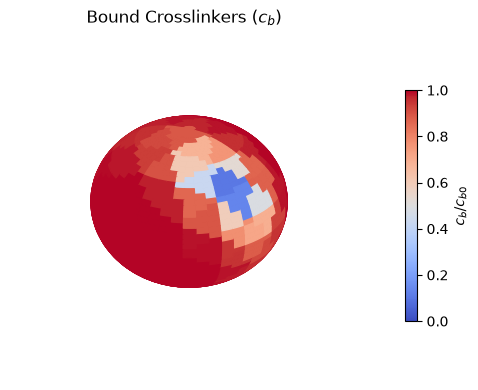

In [ ]:
from plotting import plot_microsphere

plot_microsphere(mf0i, cb_array1s, cb_array1s[0], title="Bound Crosslinkers ($c_b$)", path=None)

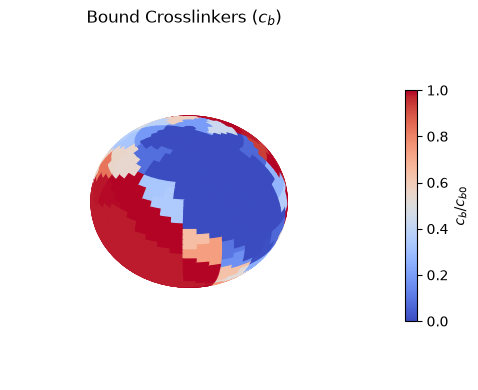

In [ ]:
from plotting import plot_microsphere

plot_microsphere(mf0i, cb_array10s, cb_array10s[0], title="Bound Crosslinkers ($c_b$)", path=None)

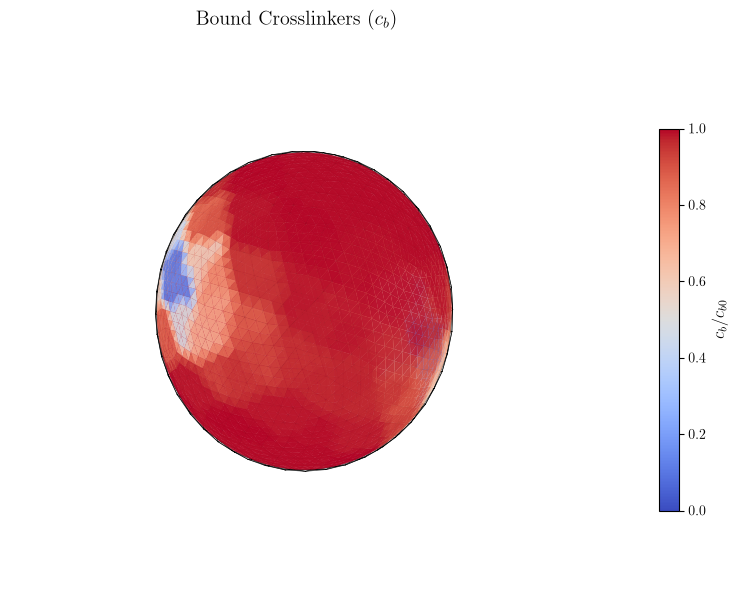

In [ ]:
import plots_math

plots_math.plot_microsphere_mathematica_style(mf0i, cb_array1s, 0.000203)

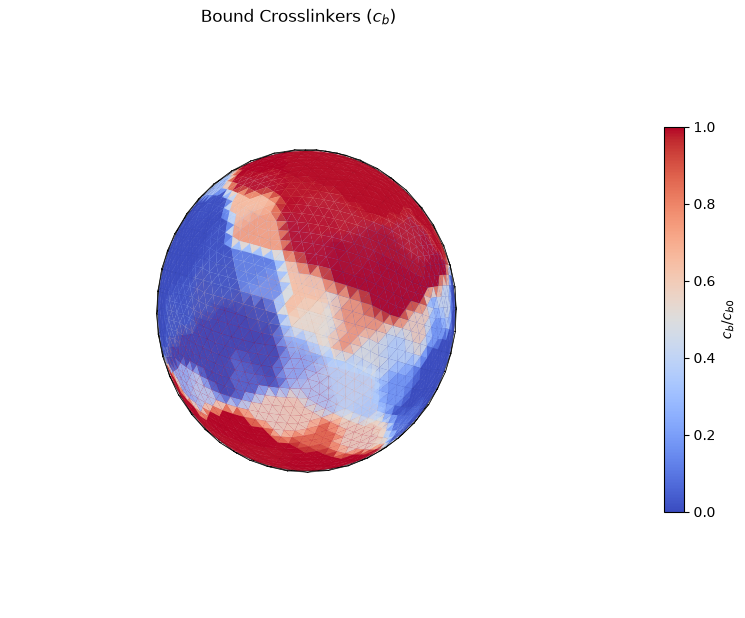

In [4]:
import plots_math

plots_math.plot_microsphere_mathematica_style(mf0i, cb_array10s, 0.000204, title="Bound Crosslinkers ($c_b$)")

/home/luis/Desktop/PhD/UEL-dynamicCL/python_scripts


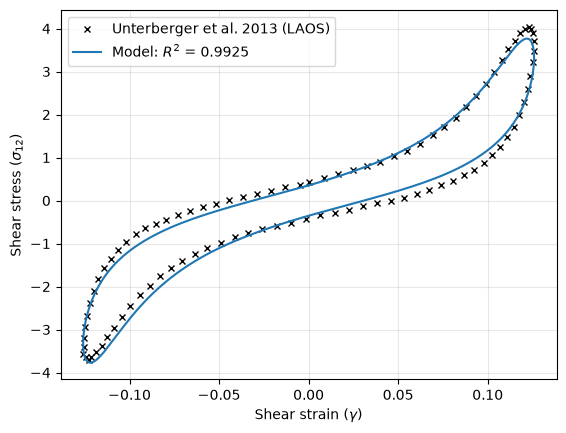

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
print(os.getcwd())

file = "optimisation_runs/c5_w15_plate_guo_dxs/best_loop.npz"

model_data = np.load(file, allow_pickle=True)

gamma_last = model_data['gamma']
sigma_last = model_data['sigma']

d = np.loadtxt('validation_data/unterberger2013_fig4a_laos_dataset0.csv', delimiter=',', comments='#')
gamma, sigma, branch = d[:, 0], d[:, 1], d[:, 2]
# g0, s0, b0 = d0[:, 0], d0[:, 1], d0[:, 2]

dg_last = np.gradient(gamma_last)
s_model = np.empty_like(sigma)
for b in (1, -1):
    msk = dg_last > 0 if b == 1 else dg_last < 0
    o = np.argsort(gamma_last[msk])
    s_model[branch == b] = np.interp(gamma[branch == b], gamma_last[msk][o], sigma_last[msk][o])
rmse = np.sqrt(np.mean((s_model - sigma)**2))
r2 = 1.0 - np.sum((s_model - sigma)**2) / np.sum((sigma - np.mean(sigma))**2)



plt.plot(gamma, sigma, 'kx', ms=5, label='Unterberger et al. 2013 (LAOS)')
plt.xlabel('Shear strain ($\\gamma$)')
# plt.xlabel('Shear Strain ($\\gamma$)')
plt.ylabel('Shear stress ($\\sigma_{12}$)')
plt.plot(model_data['gamma'], model_data['sigma'], 
         label=f'Model: $R^2$ = {r2:.4f}')
plt.grid(alpha=0.3)
plt.legend()
plt.savefig('figures/c5_w15_plate_guo_dxs_best_loop.pdf', bbox_inches='tight')


/home/luis/Desktop/PhD/UEL-dynamicCL/python_scripts


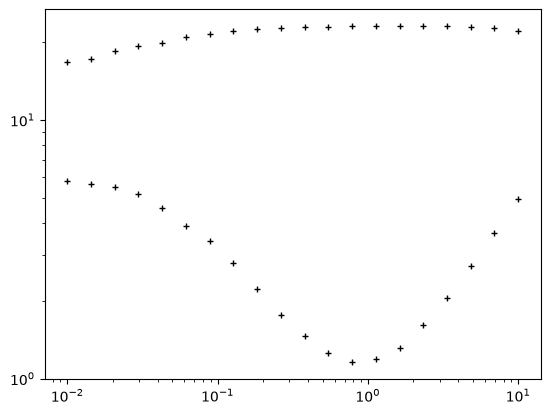

In [10]:
import os
import matplotlib.pyplot as plt
import numpy as np
print(os.getcwd())

# file = "optimisation_runs/sweep_w15_c5_mech/best_loop.npz"

model_data = np.load(file, allow_pickle=True)

gamma_last = model_data['gamma']
sigma_last = model_data['sigma']

d = np.loadtxt('validation_data/5_G_.csv', delimiter=',', comments='#')
gamma, sigma = d[:, 0], d[:, 1]
d2 = np.loadtxt('validation_data/5_G__.csv', delimiter=',', comments='#')
gamma2, sigma2 = d2[:, 0], d2[:, 1]
# g0, s0, b0 = d0[:, 0], d0[:, 1], d0[:, 2]

# dg_last = np.gradient(gamma_last)
# s_model = np.empty_like(sigma)
# for b in (1, -1):
#     msk = dg_last > 0 if b == 1 else dg_last < 0
#     o = np.argsort(gamma_last[msk])
#     s_model[branch == b] = np.interp(gamma[branch == b], gamma_last[msk][o], sigma_last[msk][o])
# rmse = np.sqrt(np.mean((s_model - sigma)**2))
# r2 = 1.0 - np.sum((s_model - sigma)**2) / np.sum((sigma - np.mean(sigma))**2)



plt.loglog(gamma, sigma, 'k+', ms=5, label='$G\'$')
plt.loglog(gamma2, sigma2, 'k+', ms=5, label='$G\'\'$')
# plt.xlabel('Shear strain ($\\gamma$)')
# # plt.xlabel('Shear Strain ($\\gamma$)')
# plt.ylabel('Shear stress ($\\sigma_{12}$)')
# plt.plot(model_data['gamma'], model_data['sigma'], 
#          label=f'Model: $R^2$ = {r2:.4f}')
# plt.grid(alpha=0.3)
# plt.legend()
# plt.savefig('figures/sweep_w15_c5_mech_best_loop.pdf', bbox_inches='tight')
